# Étape 4 : prévoir l'affluence de J+1 à J+7

**Question.** Combien de voyageurs monteront demain (et jusqu'à J+7) dans chaque gare, sur chaque
ligne et dans chaque tranche horaire, avec quelle incertitude, et pourquoi ?

**Formulation.** `voyageurs = niveau habituel × indice du jour`

* **niveau habituel** : médiane du compte officiel (étape 3) de la gare, de la ligne, de la tranche
  et de la catégorie de jour IDFM ;
* **indice du jour** : trois modèles LightGBM quantile (P10, P50, P90) appris sur les écarts à ce
  niveau, à partir du calendrier (jour de semaine, férié, vacances, pont), pondérés par le score de
  confiance de l'étape 2 ;
* **intervalle** recalibré sur les 60 derniers jours connus pour couvrir réellement 80 % des cas ;
* **explication** de chaque prévision par TreeSHAP (natif LightGBM), convertie en voyageurs.

La référence à battre est le niveau habituel seul : c'est ce qu'un agent prévoirait « de tête ».

```bash
pip install -e ".[notebooks]"
comptage qualify && comptage compte-officiel && comptage prevoir
jupyter lab notebooks/03_prediction_affluence.ipynb
```

> Uniquement des données Open Data publiques (SNCF, Île-de-France Mobilités, Open-Meteo).

In [1]:
import dataclasses

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from comptage_train import prediction as P, warehouse
from comptage_train.settings import data_dir

DATA = data_dir()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

con = warehouse.connect_derived(DATA)
P.meteo_journaliere(con, DATA)
cfg = P.load_config()
hist = P.historique(con, cfg)
modalites = {c: sorted(hist[c].dropna().unique().tolist()) for c in P.CATEGORIELLES}
debut_test = hist["date"].max() - pd.Timedelta(days=cfg.test_jours - 1)
app, test = hist[hist["date"] < debut_test], hist[hist["date"] >= debut_test]
print(f"historique : {len(hist):,} lignes, {hist['date'].min()} -> {hist['date'].max()}")
print(f"apprentissage : {len(app):,} lignes ; test : {len(test):,} lignes à partir du {debut_test.date()}")

historique : 668,790 lignes, 2025-07-01 00:00:00 -> 2026-06-30 00:00:00
apprentissage : 557,720 lignes ; test : 111,070 lignes à partir du 2026-05-02


## 1. Ce qu'on apprend

L'historique ne contient que le compte officiel **mesuré** ou **réconcilié avec les validations
IDFM** : l'extrapolé est déjà une estimation, l'apprendre reviendrait à apprendre nos propres
hypothèses. La fin de l'historique est donc la dernière date publiée par IDFM (environ 4 mois de
retard), et la période de test est la plus récente connue.

In [2]:
hist.groupby(hist["date"].dt.to_period("M")).agg(lignes=("voyageurs", "size"),
                                                 voyageurs=("voyageurs", "sum"),
                                                 score_moyen=("score_confiance", "mean")).round(1)

,lignes,voyageurs,score_moyen
date,,,
2025-07,55985,60311234,78.1
2025-08,55305,47239811,78.1
2025-09,54695,67092016,78.1
2025-10,56530,71806378,78.1
2025-11,54795,66832696,78.1
2025-12,56725,66553619,78.1
2026-01,57445,69906752,78.1
2026-02,51610,69593149,78.1
2026-03,57265,76911051,78.1


## 2. Le modèle bat-il la référence ?

Erreur pondérée (WAPE) = somme des erreurs absolues / somme des voyageurs, sur la période de test.

In [3]:
def evaluer(config, label):
    m = P._apprendre(app, config, modalites)
    p = m.predire(test)
    p["err_modele"] = (p["p50"] - p["voyageurs"]).abs()
    p["err_ref"] = (p["niveau_habituel"] - p["voyageurs"]).abs()
    y = p["voyageurs"].sum()
    print(f"{label:<22} WAPE modèle {p['err_modele'].sum() / y:.2%}   référence {p['err_ref'].sum() / y:.2%}")
    return m, p

modele, pred = evaluer(cfg, "calendrier seul")

calendrier seul        WAPE modèle 18.46%   référence 18.76%


## 3. Où le modèle gagne et où il perd, jour par jour

Gain = (erreur de la référence − erreur du modèle) / voyageurs du jour. Positif : le modèle fait mieux.

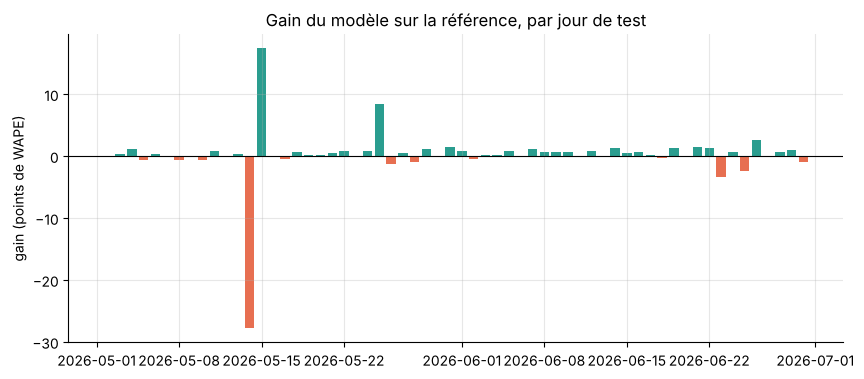

,cat,ferie,pont,gain_pts
date,,,,
2026-05-15,JOHV,0,1,17.4
2026-05-25,DIJFP,1,0,8.4
2026-06-26,JOHV,0,0,2.6
2026-05-31,DIJFP,0,0,1.5
2026-05-14,DIJFP,1,0,-27.8
2026-06-23,JOHV,0,0,-3.4
2026-06-25,JOHV,0,0,-2.3
2026-05-26,JOHV,0,0,-1.2


In [4]:
jours = pred.groupby("date").agg(voyageurs=("voyageurs", "sum"), err_modele=("err_modele", "sum"),
                                 err_ref=("err_ref", "sum"), ferie=("ferie", "max"), pont=("pont", "max"),
                                 cat=("cat_jour_idfm", "first"))
jours["gain_pts"] = 100 * (jours["err_ref"] - jours["err_modele"]) / jours["voyageurs"]
fig, ax = plt.subplots()
ax.bar(jours.index, jours["gain_pts"], color=np.where(jours["gain_pts"] >= 0, "#2a9d8f", "#e76f51"))
ax.axhline(0, color="black", lw=.8)
ax.set_ylabel("gain (points de WAPE)")
ax.set_title("Gain du modèle sur la référence, par jour de test")
plt.show()
pd.concat([jours.nlargest(4, "gain_pts"), jours.nsmallest(4, "gain_pts")])[["cat", "ferie", "pont", "gain_pts"]].round(1)

**Lecture.** Le modèle gagne nettement le pont de l'Ascension (15 mai, +17 points : le niveau
habituel d'un jour ouvré y est beaucoup trop haut) et le lundi de Pentecôte (+8). Il perd lourdement
le jeudi de l'Ascension (14 mai, −28 points) : la catégorie de jour IDFM classe déjà ce férié comme
un dimanche, et la variable `ferie` le fait baisser une seconde fois. Les autres jours, l'écart
reste de quelques points. Le gain global est donc modeste (0,3 point) et repose sur peu de jours :
c'est la principale piste d'amélioration, avec plus d'un an d'historique pour voir chaque férié
plusieurs fois.

## 4. Faut-il ajouter la météo ?

On réapprend le même modèle en ajoutant la pluie et la neige du jour (archive Open-Meteo).

In [5]:
avec_meteo = dataclasses.replace(cfg, variables=cfg.variables + ["pluie_mm", "neige_cm"])
_ = evaluer(avec_meteo, "calendrier + météo")

calendrier + météo     WAPE modèle 19.25%   référence 18.76%


**Décision : météo écartée du modèle.** Elle dégrade l'erreur sur la période de test et la fait
repasser au-dessus de la référence. Avec un an d'historique, les quelques jours de forte pluie ou de
neige se confondent avec des grèves ou des changements de saison : le modèle apprend du bruit.
C'est cohérent avec l'étape 3, où la météo n'expliquait que 6 % des écarts journaliers de
validations. Elle reste affichée dans D4 et dans l'API (`source_meteo`) et sera réévaluée quand
l'historique aura deux hivers.

## 5. L'intervalle P10-P90 dit-il vrai ?

Un intervalle à 80 % doit contenir la vérité 8 fois sur 10. Les quantiles bruts sont trop étroits :
les écarts d'un même jour sont liés entre toutes les gares (un pont touche tout le réseau), ce que
le modèle ne voit pas ligne par ligne. On élargit chaque côté d'un facteur mesuré sur la période de
test (recalibrage conforme).

In [6]:
evaluation = pd.read_parquet(DATA / "gold" / "modele_evaluation.parquet").set_index("metrique")["valeur"]
evaluation.round(4)

metrique
lignes_test                       1.110700e+05
debut_test                        2.026050e+07
wape_modele_p50                   1.846000e-01
wape_reference_niveau_habituel    1.876000e-01
couverture_brute_p10_p90          6.321000e-01
couverture_recalibree_p10_p90     7.872000e-01
recalibrage_bas                   2.102700e+00
recalibrage_haut                  1.602200e+00
Name: valeur, dtype: float64

In [7]:
r = modele.recalibrage if modele.recalibrage != {"bas": 1.0, "haut": 1.0} else {
    "bas": evaluation["recalibrage_bas"], "haut": evaluation["recalibrage_haut"]}
lo = pred["p50"] - r["bas"] * (pred["p50"] - pred["p10"])
hi = pred["p50"] + r["haut"] * (pred["p90"] - pred["p50"])
y = pred["voyageurs"]
couverture = pd.DataFrame({"brute": (y >= pred["p10"]) & (y <= pred["p90"]), "recalibrée": (y >= lo) & (y <= hi),
                           "tranche": pred["tranche_horaire"]}).groupby("tranche")[["brute", "recalibrée"]].mean()
couverture.round(3)

,brute,recalibrée
tranche,,
Après 20h,0.673,0.808
Avant 6h,0.640,0.778
De 10h à 16h,0.619,0.786
De 16h à 20h,0.631,0.793
De 6h à 10h,0.597,0.770


## 6. Quelles variables comptent ?

Contribution moyenne absolue (TreeSHAP) à la prévision P50, en voyageurs, sur la période de test.

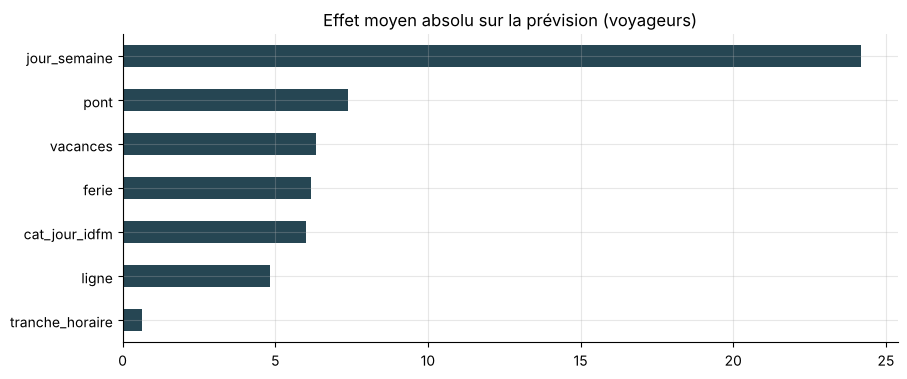

In [8]:
contrib = modele.boosters[0.5].predict(modele.matrice(pred), pred_contrib=True)[:, :-1]
importance = pd.Series(np.abs(contrib * pred["niveau_habituel"].to_numpy()[:, None]).mean(axis=0),
                       index=cfg.variables).sort_values()
importance.plot.barh(title="Effet moyen absolu sur la prévision (voyageurs)", color="#264653")
plt.show()

## 7. Exemple : une prévision expliquée

La prévision publiée (`gold/previsions.parquet`) se lit comme une addition : niveau habituel, écart
moyen du modèle, puis l'effet de chaque variable. C'est exactement ce qu'affichent D4 et l'API.

In [9]:
from comptage_train.api import explication

prev = pd.read_parquet(DATA / "gold" / "previsions.parquet")
ex = prev[(prev["code_gare"] == "87271031") & (prev["tranche_horaire"] == "De 6h à 10h")].iloc[0]
print(ex["nom_gare"], ex["ligne"], ex["date"], ex["tranche_horaire"], "->", ex["niveau"])
print(f"P10-P90 : {ex['p10']} - {ex['p90']}")
print(explication(ex))
pd.DataFrame(list(ex["contributions"])).sort_values("effet_voyageurs", key=abs, ascending=False)

PARIS-GARE-DU-NORD B 2026-10-22 00:00:00 De 6h à 10h -> MOYENNE
P10-P90 : 12240 - 27125
niveau habituel 21209 voy. | jour de la semaine (4) +319 | jour férié (0) +237 | vacances scolaires (1) -131 | autres effets -21 = 21613 voyageurs prévus


,variable,valeur,effet_voyageurs
2,jour_semaine,4,319.4
4,ferie,0,237.2
5,vacances,1,-131.4
1,ligne,B,-128.4
3,cat_jour_idfm,JOVS,55.3
6,pont,0,48.2
0,tranche_horaire,De 6h à 10h,7.4


In [10]:
prev.groupby("niveau").size().rename("prévisions").to_frame().assign(part=lambda d: (d["prévisions"] / d["prévisions"].sum()).round(3))

,prévisions,part
niveau,,
FAIBLE,6552,0.503
FORTE,1639,0.126
MOYENNE,4829,0.371


## 8. Limites connues

* **Pas de capacité des trains en Open Data** : le niveau FAIBLE / MOYENNE / FORTE compare
  l'intensité prévue (voyageurs par heure) à l'historique de la même gare et ligne (médiane et
  85e centile), pas à un taux de remplissage.
* **Retard IDFM** : on prévoit J+1 à J+7 à partir d'un historique qui s'arrête environ 4 mois plus
  tôt. Le niveau habituel suit donc avec retard une tendance de fond (hausse de fréquentation,
  travaux longs).
* **Événements non calendaires** (grèves, incidents, concerts, travaux) : invisibles pour le modèle,
  ce sont les jours où il perd (§3). Une source Open Data d'information voyageurs ou de travaux
  planifiés serait la prochaine variable à évaluer.
* **Météo** : écartée (§4), à réévaluer avec deux hivers d'historique.
* **Gares** : seules les gares × lignes étalonnées à l'étape 3 sont prévues.